In [1]:
# 1. Import các thư viện cần thiết và hiển thị phiên bản đang sử dụng
import sys
sys.dont_write_bytecode = True
from pathlib import Path
from time import perf_counter
from importlib.metadata import version
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from xgboost import XGBRegressor

print("NumPy:", np.__version__, "| Pandas:", pd.__version__,
      "| Scikit-learn:", version("scikit-learn"), "| XGBoost:", version("xgboost"))


NumPy: 2.1.3 | Pandas: 2.3.3 | Scikit-learn: 1.7.1 | XGBoost: 3.3.0


In [2]:
# 2. Giữ đường dẫn và cấu hình chung: tối đa 1200 cây, early stopping 50 vòng
ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents]
             if (path / "data/processed/Hanoi_final.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Hãy chạy notebook từ thư mục project hoặc XGBoost.")
TRAIN_FILE = ROOT / "data/processed/Hanoi_final.csv"
TEST_FILE = ROOT / "data/processed/Hanoi_test_final.csv"
FEATURE_FILE = ROOT / "data_processing/feature_selection.json"
VALID_START = pd.Timestamp("2025-01-01")
TEST_START = pd.Timestamp("2026-01-01")
TEST_END = pd.Timestamp("2026-09-29 23:00")
target = "temperature_2m"

params = {
    "objective": "reg:squarederror",
    "n_estimators": 1200,
    "max_depth": 5,
    "learning_rate": 0.05,
    "subsample": 0.9,
    "colsample_bytree": 0.9,
    "reg_lambda": 1.0,
    "eval_metric": "rmse",
    "tree_method": "hist",
    "device": "cpu",
    "n_jobs": 4,
    "random_state": 42,
    "early_stopping_rounds": 50,
}
print("Project:", ROOT)
display(pd.DataFrame([params]))


Project: D:\Weather-Forecasting-AIL


,objective,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,reg_lambda,eval_metric,tree_method,device,n_jobs,random_state,early_stopping_rounds
0,reg:squarederror,1200,5,0.05,0.9,0.9,1.0,rmse,hist,cpu,4,42,50


In [3]:
# 3. Đọc hai CSV processed và kiểm tra schema, giá trị thiếu, dữ liệu số và chuỗi giờ
train_data = pd.read_csv(TRAIN_FILE, parse_dates=["time"])
test_data = pd.read_csv(TEST_FILE, parse_dates=["time"])
assert train_data.columns.equals(test_data.columns)
quality_rows = []
for name, frame in [("Lịch sử 2010–2025", train_data), ("Test 2026", test_data)]:
    if frame.empty or frame.isna().any().any():
        raise ValueError(f"{name}: dữ liệu rỗng hoặc có giá trị thiếu.")
    if frame["time"].duplicated().any() or not frame["time"].diff().iloc[1:].eq(pd.Timedelta(hours=1)).all():
        raise ValueError(f"{name}: thời gian phải duy nhất, tăng liên tục từng giờ.")
    if not np.isfinite(frame.select_dtypes(include="number").to_numpy()).all():
        raise ValueError(f"{name}: có giá trị số không hữu hạn.")
    quality_rows.append({
        "Dữ liệu": name, "Số dòng": len(frame), "Số cột": len(frame.columns),
        "Từ": frame["time"].min(), "Đến": frame["time"].max(),
        "Ô thiếu": int(frame.isna().sum().sum()),
    })
assert train_data["time"].max() < TEST_START
assert test_data["time"].min() == TEST_START and test_data["time"].max() == TEST_END
assert test_data["time"].min() - train_data["time"].max() == pd.Timedelta(hours=1)
display(pd.DataFrame(quality_rows))
print("Ba dòng đầu dữ liệu lịch sử:")
display(train_data.head(3))
print("Ba dòng đầu dữ liệu test:")
display(test_data.head(3))


,Dữ liệu,Số dòng,Số cột,Từ,Đến,Ô thiếu
0,Lịch sử 2010–2025,140232,41,2010-01-02,2025-12-31 23:00:00,0
1,Test 2026,6528,41,2026-01-01,2026-09-29 23:00:00,0


Ba dòng đầu dữ liệu lịch sử:


,time,city,latitude,longitude,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,rain,pressure_msl,surface_pressure,cloud_cover,wind_speed_10m,wind_speed_100m,wind_direction_10m_sin,wind_direction_10m_cos,wind_direction_100m_sin,wind_direction_100m_cos,wind_gusts_10m,et0_fao_evapotranspiration,soil_temperature_0_to_7cm,soil_temperature_28_to_100cm,soil_temperature_100_to_255cm,soil_moisture_0_to_7cm,soil_moisture_7_to_28cm,soil_moisture_28_to_100cm,soil_moisture_100_to_255cm,weather_code,hour_sin,hour_cos,day_of_year_sin,day_of_year_cos,temp_lag_1h,temp_lag_3h,temp_lag_24h,temp_delta_1h,temp_rolling_mean_3h,dew_point_2m,vapour_pressure_deficit,soil_temperature_7_to_28cm,is_day
0,2010-01-02 00:00:00,Hanoi,21.0285,105.8542,16.3,96,17.4,0.3,0.3,1015.8,1013.5,100,5.4,11.0,6.975647e-02,0.997564,0.190809,0.981627,13.0,0.0,17.8,21.3,25.0,0.323,0.258,0.289,0.377,51,0.000000,1.000000,0.017213,0.999852,16.8,17.2,16.7,-0.5,16.666667,15.6,0.08,18.9,0
1,2010-01-02 01:00:00,Hanoi,21.0285,105.8542,16.4,95,17.6,0.0,0.0,1015.3,1013.0,100,5.1,10.4,6.975647e-02,0.997564,0.241922,0.970296,11.9,0.0,17.8,21.3,25.0,0.322,0.259,0.289,0.377,3,0.258819,0.965926,0.017931,0.999839,16.3,16.9,16.8,0.1,16.500000,15.6,0.09,18.9,0
2,2010-01-02 02:00:00,Hanoi,21.0285,105.8542,16.4,95,17.7,0.2,0.2,1014.6,1012.3,100,4.3,8.8,-2.449294e-16,1.000000,0.156434,0.987688,10.4,0.0,17.9,21.3,24.9,0.324,0.259,0.289,0.377,51,0.500000,0.866025,0.018648,0.999826,16.4,16.8,16.8,0.0,16.366667,15.6,0.09,18.8,0


Ba dòng đầu dữ liệu test:


,time,city,latitude,longitude,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,rain,pressure_msl,surface_pressure,cloud_cover,wind_speed_10m,wind_speed_100m,wind_direction_10m_sin,wind_direction_10m_cos,wind_direction_100m_sin,wind_direction_100m_cos,wind_gusts_10m,et0_fao_evapotranspiration,soil_temperature_0_to_7cm,soil_temperature_28_to_100cm,soil_temperature_100_to_255cm,soil_moisture_0_to_7cm,soil_moisture_7_to_28cm,soil_moisture_28_to_100cm,soil_moisture_100_to_255cm,weather_code,hour_sin,hour_cos,day_of_year_sin,day_of_year_cos,temp_lag_1h,temp_lag_3h,temp_lag_24h,temp_delta_1h,temp_rolling_mean_3h,dew_point_2m,vapour_pressure_deficit,soil_temperature_7_to_28cm,is_day
0,2026-01-01 00:00:00,Hanoi,21.0285,105.8542,20.5,92,22.7,0.0,0.0,1013.0,1010.8,99,8.6,16.4,0.961262,-0.275637,0.920505,-0.390731,15.1,0.01,21.5,21.1,23.3,0.299,0.302,0.303,0.387,3,0.000000,1.000000,0.000000,1.000000,20.6,20.6,19.6,-0.1,20.466667,19.1,0.20,21.2,0
1,2026-01-01 01:00:00,Hanoi,21.0285,105.8542,20.7,90,22.9,0.2,0.2,1013.0,1010.8,100,8.5,15.7,0.978148,-0.207912,0.945519,-0.325568,13.7,0.01,21.7,21.1,23.3,0.300,0.302,0.303,0.387,51,0.258819,0.965926,0.000717,1.000000,20.5,20.3,20.0,0.2,20.600000,19.0,0.24,21.1,0
2,2026-01-01 02:00:00,Hanoi,21.0285,105.8542,20.7,90,22.8,0.2,0.2,1012.8,1010.6,100,8.3,15.1,0.970296,-0.241922,0.939693,-0.342020,17.3,0.01,21.8,21.1,23.3,0.301,0.302,0.303,0.387,51,0.500000,0.866025,0.001435,0.999999,20.7,20.6,19.8,0.0,20.633333,19.0,0.24,21.0,0


In [4]:
# 4. Dùng bộ feature ML đã chọn và ghép nhãn t+1, kể cả ranh giới 2025–2026
selection = json.loads(FEATURE_FILE.read_text(encoding="utf-8"))
features = selection["selected_features"]
metadata = {"time", "city", "latitude", "longitude"}
assert selection["target"] == target and selection["horizon_hours"] == 1
assert len(features) == len(set(features)) and target in features
assert not set(features) & (metadata | {"label_time", "temperature_next_hour"})
assert set(features).issubset(train_data.columns)
assert all(pd.api.types.is_numeric_dtype(train_data[name]) for name in features)
assert pd.Timestamp(selection["selection_train_label_end"]) < VALID_START
print(f"Sử dụng {len(features)} feature dạng bảng; không mở rộng cửa sổ 768 đầu vào, không scaling.")
display(pd.DataFrame({"Feature": features}))

data = pd.concat([train_data, test_data], ignore_index=True)
# Đối chiếu các cột lịch sử có sẵn với quan sát hiện tại/quá khứ, không tạo lại pipeline.
for lag in (1, 3, 24):
    np.testing.assert_allclose(data[f"temp_lag_{lag}h"].iloc[lag:],
                               data[target].iloc[:-lag], rtol=1e-7, atol=1e-7)
np.testing.assert_allclose(data["temp_delta_1h"].iloc[1:],
                           data[target].diff().iloc[1:], atol=1e-7)
np.testing.assert_allclose(data["temp_rolling_mean_3h"].iloc[2:],
                           data[target].rolling(3).mean().iloc[2:], atol=1e-7)

forecast = data[["time", *features]].copy()
forecast["label_time"] = data["time"].shift(-1)
forecast["temperature_next_hour"] = data[target].shift(-1)
forecast = forecast.iloc[:-1].reset_index(drop=True)
assert len(forecast) == len(data) - 1
assert not forecast.isna().any().any()
assert (forecast["label_time"] - forecast["time"]).eq(pd.Timedelta(hours=1)).all()
np.testing.assert_array_equal(forecast["temperature_next_hour"], data[target].iloc[1:])
assert forecast["label_time"].iloc[-1] == TEST_END
print("Hàng cuối đã được bỏ vì không có nhãn giờ tiếp theo.")


Sử dụng 33 feature dạng bảng; không mở rộng cửa sổ 768 đầu vào, không scaling.


,Feature
0,temperature_2m
1,relative_humidity_2m
2,apparent_temperature
3,precipitation
4,rain
5,pressure_msl
6,surface_pressure
7,cloud_cover
8,wind_speed_10m
9,wind_speed_100m


Hàng cuối đã được bỏ vì không có nhãn giờ tiếp theo.


In [5]:
# 5. Chia train, validation và test theo giờ của nhãn, không chia ngẫu nhiên
train_mask = forecast["label_time"] < VALID_START
valid_mask = (forecast["label_time"] >= VALID_START) & (forecast["label_time"] < TEST_START)
test_mask = (forecast["label_time"] >= TEST_START) & (forecast["label_time"] <= TEST_END)
assert (train_mask | valid_mask | test_mask).all()
assert (train_mask.astype(int) + valid_mask.astype(int) + test_mask.astype(int)).eq(1).all()

X_train = forecast.loc[train_mask, features].astype(np.float32)
X_valid = forecast.loc[valid_mask, features].astype(np.float32)
X_test = forecast.loc[test_mask, features].astype(np.float32)
y_train = forecast.loc[train_mask, "temperature_next_hour"]
y_valid = forecast.loc[valid_mask, "temperature_next_hour"]
y_test = forecast.loc[test_mask, "temperature_next_hour"]
train_times = forecast.loc[train_mask, "label_time"]
valid_times = forecast.loc[valid_mask, "label_time"]
test_times = forecast.loc[test_mask, "label_time"]
assert train_times.max() < valid_times.min() < test_times.min()
assert valid_times.min() == VALID_START and test_times.min() == TEST_START
assert len(X_test) == len(test_data) == 6528
first_test = forecast.loc[test_mask].iloc[0]
assert first_test["time"] == pd.Timestamp("2025-12-31 23:00")
assert first_test["label_time"] == TEST_START
assert first_test["temperature_next_hour"] == test_data[target].iloc[0]

split_rows = []
for name, X, times in [("Train", X_train, train_times),
                        ("Validation", X_valid, valid_times), ("Test", X_test, test_times)]:
    split_rows.append({"Tập": name, "Số mẫu": len(X), "Feature": X.shape[1],
                       "Nhãn từ": times.min(), "Nhãn đến": times.max()})
display(pd.DataFrame(split_rows))
print("Dự báo từng giờ với thông tin đã quan sát đến t; không phải dự báo nhiều tháng từ một thời điểm.")


,Tập,Số mẫu,Feature,Nhãn từ,Nhãn đến
0,Train,131471,33,2010-01-02 01:00:00,2024-12-31 23:00:00
1,Validation,8760,33,2025-01-01 00:00:00,2025-12-31 23:00:00
2,Test,6528,33,2026-01-01 00:00:00,2026-09-29 23:00:00


Dự báo từng giờ với thông tin đã quan sát đến t; không phải dự báo nhiều tháng từ một thời điểm.


In [6]:
# 6. Khai báo đúng năm cấu hình có chủ đích, giữ độc lập mô hình của từng lượt
configurations = [
    ("A — Baseline", {"max_depth": 5, "learning_rate": 0.05, "min_child_weight": 1, "reg_lambda": 1}),
    ("B — Cây nông hơn", {"max_depth": 3, "learning_rate": 0.05, "min_child_weight": 1, "reg_lambda": 1}),
    ("C — Cây sâu hơn", {"max_depth": 7, "learning_rate": 0.05, "min_child_weight": 1, "reg_lambda": 1}),
    ("D — Learning rate nhỏ", {"max_depth": 5, "learning_rate": 0.03, "min_child_weight": 1, "reg_lambda": 1}),
    ("E — Regularization mạnh", {"max_depth": 5, "learning_rate": 0.05, "min_child_weight": 3, "reg_lambda": 10}),
]
display(pd.DataFrame([{"Cấu hình": name, **settings} for name, settings in configurations]))
print("Chỉ thử năm cấu hình này; chọn bằng Validation RMSE, không dùng test và không refit.")


,Cấu hình,max_depth,learning_rate,min_child_weight,reg_lambda
0,A — Baseline,5,0.05,1,1
1,B — Cây nông hơn,3,0.05,1,1
2,C — Cây sâu hơn,7,0.05,1,1
3,D — Learning rate nhỏ,5,0.03,1,1
4,E — Regularization mạnh,5,0.05,3,10


Chỉ thử năm cấu hình này; chọn bằng Validation RMSE, không dùng test và không refit.


In [7]:
# 7. Huấn luyện năm mô hình, kiểm tra early stopping và chọn Validation RMSE thấp nhất
models = {}
tuning_rows = []
tuning_start = perf_counter()
for name, settings in configurations:
    candidate = XGBRegressor(**{**params, **settings})
    fit_start = perf_counter()
    # Validation là tập cuối; patience được đặt trong constructor, không truyền vào fit.
    candidate.fit(
        X_train, y_train,
        eval_set=[(X_train, y_train), (X_valid, y_valid)],
        verbose=False,
    )
    elapsed = perf_counter() - fit_start
    candidate_history = candidate.evals_result()["validation_1"]["rmse"]
    actual_rounds = candidate.get_booster().num_boosted_rounds()
    best_rounds = candidate.best_iteration + 1
    assert len(candidate_history) == actual_rounds
    assert candidate.best_iteration == int(np.argmin(candidate_history))
    np.testing.assert_allclose(float(candidate.best_score), min(candidate_history))
    if actual_rounds < params["n_estimators"]:
        assert actual_rounds == best_rounds + params["early_stopping_rounds"]
        status = "Dừng sớm sau 50 vòng không cải thiện"
    else:
        status = "Chạm giới hạn 1200 vòng"
    models[name] = candidate
    tuning_rows.append({
        "Cấu hình": name, **settings,
        "Best iteration": candidate.best_iteration,
        "Số vòng đã chạy": actual_rounds,
        "Số cây dùng": best_rounds,
        "Validation RMSE": float(candidate.best_score),
        "Thời gian (giây)": elapsed,
        "Trạng thái": status,
    })
    print(f"{name}: {actual_rounds} vòng, best iteration {candidate.best_iteration}, "
          f"Validation RMSE={float(candidate.best_score):.6f}, {elapsed:.2f} giây; {status}.",
          flush=True)

tuning_seconds = perf_counter() - tuning_start
tuning_results = pd.DataFrame(tuning_rows).sort_values("Validation RMSE", kind="stable").reset_index(drop=True)
assert len(tuning_results) == len(models) == 5
assert len({id(candidate) for candidate in models.values()}) == 5
display(tuning_results.round(6))

best_row = tuning_results.iloc[0]
best_name = best_row["Cấu hình"]
model = models[best_name]
history = model.evals_result()
best_iteration = model.best_iteration
trees_used = best_iteration + 1
rounds_trained = model.get_booster().num_boosted_rounds()
best_valid_rmse = float(model.best_score)
fit_seconds = float(best_row["Thời gian (giây)"])
assert best_valid_rmse == tuning_results["Validation RMSE"].min()
print("Đã chốt:", best_name, "| Tổng thời gian tuning:", round(tuning_seconds, 2), "giây.")
print("Dùng ngay mô hình đã fit trên train; chỉ đánh giá test sau bước lựa chọn này, không refit.")


A — Baseline: 1200 vòng, best iteration 1199, Validation RMSE=0.404399, 15.39 giây; Chạm giới hạn 1200 vòng.
B — Cây nông hơn: 1200 vòng, best iteration 1198, Validation RMSE=0.423968, 11.91 giây; Chạm giới hạn 1200 vòng.
C — Cây sâu hơn: 594 vòng, best iteration 543, Validation RMSE=0.396938, 11.04 giây; Dừng sớm sau 50 vòng không cải thiện.
D — Learning rate nhỏ: 1200 vòng, best iteration 1192, Validation RMSE=0.405588, 15.52 giây; Chạm giới hạn 1200 vòng.
E — Regularization mạnh: 1200 vòng, best iteration 1199, Validation RMSE=0.400589, 15.48 giây; Chạm giới hạn 1200 vòng.


,Cấu hình,max_depth,learning_rate,min_child_weight,reg_lambda,Best iteration,Số vòng đã chạy,Số cây dùng,Validation RMSE,Thời gian (giây),Trạng thái
0,C — Cây sâu hơn,7,0.05,1,1,543,594,544,0.396938,11.043299,Dừng sớm sau 50 vòng không cải thiện
1,E — Regularization mạnh,5,0.05,3,10,1199,1200,1200,0.400589,15.479715,Chạm giới hạn 1200 vòng
2,A — Baseline,5,0.05,1,1,1199,1200,1200,0.404399,15.389698,Chạm giới hạn 1200 vòng
3,D — Learning rate nhỏ,5,0.03,1,1,1192,1200,1193,0.405588,15.518225,Chạm giới hạn 1200 vòng
4,B — Cây nông hơn,3,0.05,1,1,1198,1200,1199,0.423968,11.907035,Chạm giới hạn 1200 vòng


Đã chốt: C — Cây sâu hơn | Tổng thời gian tuning: 69.35 giây.
Dùng ngay mô hình đã fit trên train; chỉ đánh giá test sau bước lựa chọn này, không refit.


In [8]:
# 8. Đánh giá các cây tại best iteration và persistence trên cùng nhãn của ba tập
pred_train = model.predict(X_train, iteration_range=(0, trees_used))
pred_valid = model.predict(X_valid, iteration_range=(0, trees_used))
pred_test = model.predict(X_test, iteration_range=(0, trees_used))
np.testing.assert_allclose(root_mean_squared_error(y_valid, pred_valid), best_valid_rmse, rtol=1e-5)

rows = []
for name, X, y, prediction in [
    ("Train", X_train, y_train, pred_train),
    ("Validation", X_valid, y_valid, pred_valid),
    ("Test", X_test, y_test, pred_test),
]:
    assert prediction.shape == y.shape and np.isfinite(prediction).all()
    for model_name, values in [("XGBoost", prediction), ("Persistence", X[target].to_numpy())]:
        rows.append({
            "Tập": name, "Mô hình": model_name, "Số mẫu": len(y),
            "MAE (°C)": mean_absolute_error(y, values),
            "RMSE (°C)": root_mean_squared_error(y, values),
            "R²": r2_score(y, values),
        })
results = pd.DataFrame(rows)
display(results.round(6))
print("Persistence dùng nhiệt độ tại t để dự báo t+1 trên đúng các nhãn được đánh giá.")


,Tập,Mô hình,Số mẫu,MAE (°C),RMSE (°C),R²
0,Train,XGBoost,131471,0.232987,0.325568,0.996826
1,Train,Persistence,131471,0.571255,0.970847,0.971772
2,Validation,XGBoost,8760,0.278733,0.396938,0.994842
3,Validation,Persistence,8760,0.556975,0.895530,0.973744
4,Test,XGBoost,6528,0.376592,0.584329,0.988098
5,Test,Persistence,6528,0.584145,0.939567,0.969227


Persistence dùng nhiệt độ tại t để dự báo t+1 trên đúng các nhãn được đánh giá.


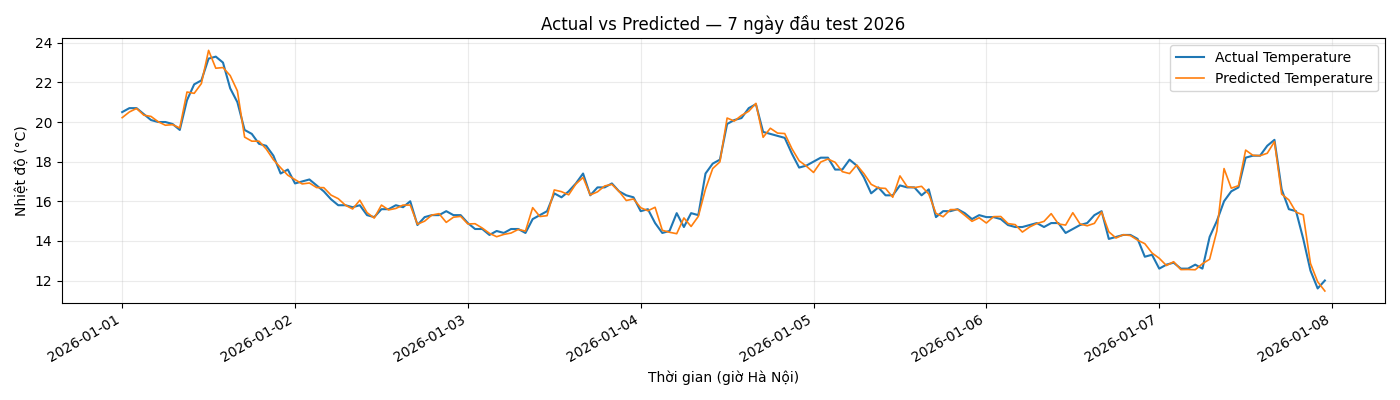

In [9]:
# 9. Vẽ Actual vs Predicted trong bảy ngày liên tục đầu tiên của test
plot_count = min(7 * 24, len(y_test))
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(test_times.iloc[:plot_count], y_test.iloc[:plot_count],
        label="Actual Temperature", linewidth=1.5)
ax.plot(test_times.iloc[:plot_count], pred_test[:plot_count],
        label="Predicted Temperature", linewidth=1.2)
ax.set(title="Actual vs Predicted — 7 ngày đầu test 2026",
       xlabel="Thời gian (giờ Hà Nội)", ylabel="Nhiệt độ (°C)")
ax.grid(alpha=0.25)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
plt.close(fig)


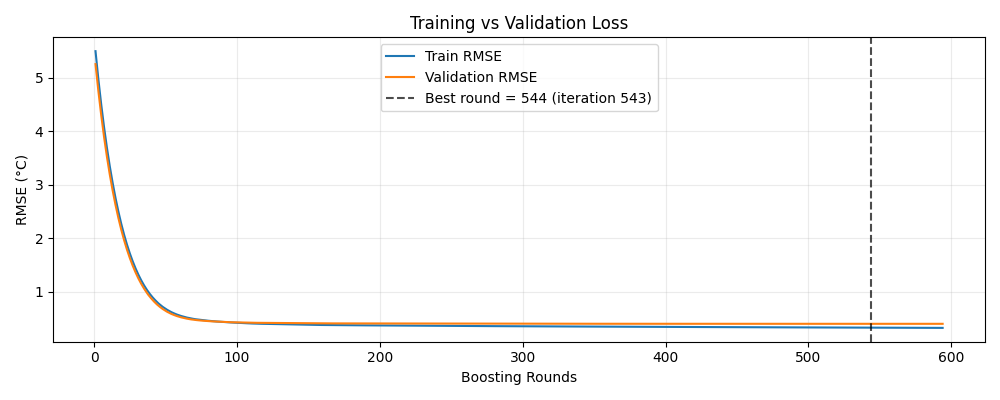

In [10]:
# 10. Vẽ lịch sử Train/Validation RMSE và đánh dấu boosting round tốt nhất
round_numbers = np.arange(1, rounds_trained + 1)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(round_numbers, history["validation_0"]["rmse"], label="Train RMSE")
ax.plot(round_numbers, history["validation_1"]["rmse"], label="Validation RMSE")
ax.axvline(trees_used, color="black", linestyle="--", alpha=0.7,
           label=f"Best round = {trees_used} (iteration {best_iteration})")
ax.set(title="Training vs Validation Loss", xlabel="Boosting Rounds", ylabel="RMSE (°C)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)


,Feature,Total gain,Gain (%)
0,temperature_2m,3.131798e+07,77.5346
1,apparent_temperature,7.587942e+06,18.7856
2,temp_rolling_mean_3h,4.754764e+05,1.1771
3,hour_sin,3.693732e+05,0.9145
4,hour_cos,2.762486e+05,0.6839
5,et0_fao_evapotranspiration,1.804022e+05,0.4466
6,temp_lag_3h,2.709218e+04,0.0671
7,cloud_cover,2.344979e+04,0.0581
8,relative_humidity_2m,1.926602e+04,0.0477
9,precipitation,1.326805e+04,0.0328


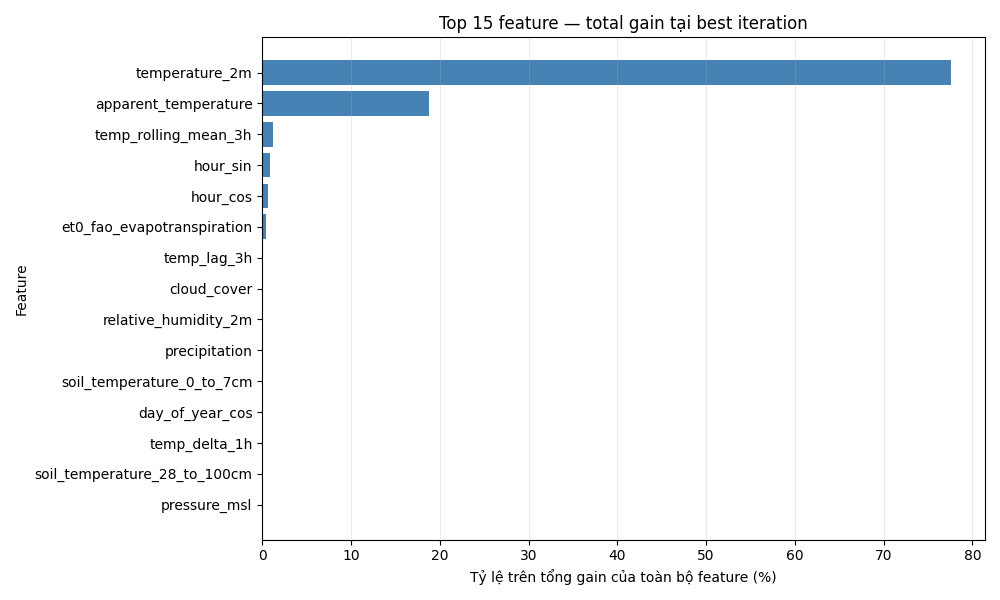

Gain được chuẩn hóa trên toàn bộ feature; Top 15 có thể không cộng thành 100%.


In [11]:
# 11. Vẽ Top 15 feature theo total_gain, chỉ lấy các cây được dùng dự đoán
best_booster = model.get_booster()[:trees_used]
assert best_booster.num_boosted_rounds() == trees_used
assert best_booster.feature_names == features
gains = best_booster.get_score(importance_type="total_gain")
importance = pd.DataFrame({"Feature": features,
                            "Total gain": [gains.get(name, 0.0) for name in features]})
total_gain = importance["Total gain"].sum()
assert total_gain > 0
importance["Gain (%)"] = 100 * importance["Total gain"] / total_gain
importance = importance.sort_values("Total gain", ascending=False).reset_index(drop=True)
display(importance.head(15).round(4))
top_features = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_features["Feature"], top_features["Gain (%)"], color="steelblue")
ax.set(title="Top 15 feature — total gain tại best iteration",
       xlabel="Tỷ lệ trên tổng gain của toàn bộ feature (%)", ylabel="Feature")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()
plt.close(fig)
print("Gain được chuẩn hóa trên toàn bộ feature; Top 15 có thể không cộng thành 100%.")


In [12]:
# 12. Tổng kết cấu hình được chọn, thời gian tuning và kết quả backtest
test_score = results[(results["Tập"] == "Test") & (results["Mô hình"] == "XGBoost")].iloc[0]
baseline_score = results[(results["Tập"] == "Test") & (results["Mô hình"] == "Persistence")].iloc[0]
mae_improvement = 100 * (1 - test_score["MAE (°C)"] / baseline_score["MAE (°C)"])
summary = pd.DataFrame([{
    "Cấu hình tốt nhất": best_name,
    "Feature": len(features), "Train": len(y_train), "Validation": len(y_valid), "Test": len(y_test),
    "Best iteration (từ 0)": best_iteration, "Số vòng đã chạy": rounds_trained, "Số cây dùng": trees_used,
    "Train cấu hình tốt nhất (giây)": fit_seconds, "Tổng tuning (giây)": tuning_seconds,
    "Validation RMSE (°C)": best_valid_rmse,
    "Test MAE (°C)": test_score["MAE (°C)"], "Test RMSE (°C)": test_score["RMSE (°C)"],
    "Test R²": test_score["R²"], "Cải thiện MAE so persistence (%)": mae_improvement,
}])
display(summary.round(6))
print("Trạng thái cấu hình được chọn:", best_row["Trạng thái"])
print("Chỉ thử đúng năm cấu hình, chọn bằng validation; đánh giá test một lần và không refit.")
print("Test 2026 đã từng được nhóm sử dụng: đây là backtest, không phải bằng chứng hoàn toàn độc lập.")
print("Không kết luận tốt hơn RF/LR khi chưa đánh giá cùng điều kiện.")
print("Đặc trưng tương quan có thể chia sẻ gain; total_gain không chứng minh quan hệ nhân quả.")
print("Chỉ hiển thị kết quả trong notebook; không ghi dữ liệu, model hoặc biểu đồ ra file riêng.")


,Cấu hình tốt nhất,Feature,Train,Validation,Test,Best iteration (từ 0),Số vòng đã chạy,Số cây dùng,Train cấu hình tốt nhất (giây),Tổng tuning (giây),Validation RMSE (°C),Test MAE (°C),Test RMSE (°C),Test R²,Cải thiện MAE so persistence (%)
0,C — Cây sâu hơn,33,131471,8760,6528,543,594,544,11.043299,69.345021,0.396938,0.376592,0.584329,0.988098,35.531041


Trạng thái cấu hình được chọn: Dừng sớm sau 50 vòng không cải thiện
Chỉ thử đúng năm cấu hình, chọn bằng validation; đánh giá test một lần và không refit.
Test 2026 đã từng được nhóm sử dụng: đây là backtest, không phải bằng chứng hoàn toàn độc lập.
Không kết luận tốt hơn RF/LR khi chưa đánh giá cùng điều kiện.
Đặc trưng tương quan có thể chia sẻ gain; total_gain không chứng minh quan hệ nhân quả.
Chỉ hiển thị kết quả trong notebook; không ghi dữ liệu, model hoặc biểu đồ ra file riêng.
